# On-Going 2 · Phân tích và dự đoán bệnh tim mạch

On-Going 1 đã tạo tệp `cleaned_cardio.csv`. Đặt tệp này cùng thư mục với notebook (trên Colab, tải vào mục **Files**), rồi chạy các ô từ trên xuống. Mỗi hàng là một người. Nhãn `cardio` bằng 0 nếu không có bệnh và bằng 1 nếu có bệnh.

Ta sẽ tìm những chỉ số khác nhau giữa hai nhóm, dùng chúng để dự đoán nhãn, rồi kiểm tra mô hình bỏ sót bao nhiêu trường hợp.

# Phần 1. Khám phá dữ liệu

#### 1.1. Đọc dữ liệu và xem phân bố

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn đến tệp dữ liệu đã làm sạch
data_path = "cleaned_cardio.csv"

# pd.read_csv() đọc tệp CSV và trả về một bảng dữ liệu (DataFrame)
cardio_data = pd.read_csv(data_path)

In [2]:
# Kiểm tra thông tin kích thước và xem qua dữ liệu

# .shape trả về (số hàng, số cột) của bảng dữ liệu
print("Kích thước dữ liệu:", cardio_data.shape)

# .columns.tolist() lấy tên các cột và chuyển thành list
column_names = cardio_data.columns.tolist()
print("Tên cột:", column_names)

# .head() lấy 5 hàng đầu tiên; display() hiển thị bảng đẹp hơn print() trong notebook
display(cardio_data.head())

Kích thước dữ liệu: (59187, 13)
Tên cột: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,8,60,1,151,67.0,120,80,2,2,0,0,0,0


**Hai nhóm có bao nhiêu người?** Bảng cho biết tỷ lệ phần trăm, còn chiều cao của cột cho biết số người.


Tỷ lệ cardio (%):
cardio
0    48.97
1    51.03
Name: proportion, dtype: float64


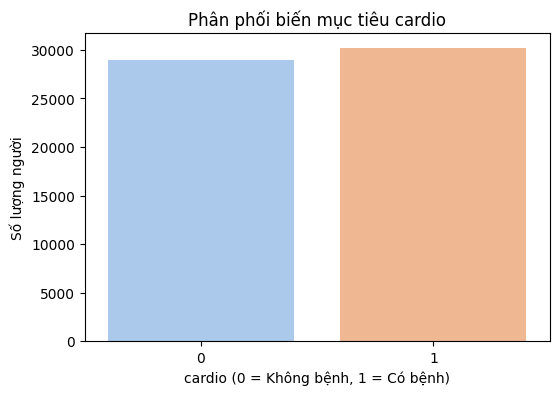

In [3]:
# Tỷ lệ phân phối của biến mục tiêu cardio
print("\nTỷ lệ cardio (%):")

# Bước 1: value_counts(normalize=True) đếm mỗi giá trị và trả về tỷ lệ (từ 0 đến 1)
cardio_percentage = cardio_data["cardio"].value_counts(normalize=True)

# Bước 2: sort_index() sắp xếp theo giá trị nhãn (0 trước, 1 sau)
cardio_percentage = cardio_percentage.sort_index()

# Bước 3: nhân 100 để đổi sang phần trăm
cardio_percentage = cardio_percentage * 100

# Bước 4: round(2) làm tròn 2 chữ số thập phân
cardio_percentage = cardio_percentage.round(2)

print(cardio_percentage)

# Trực quan hóa biến mục tiêu
# figsize=(6, 4): biểu đồ rộng 6 inch, cao 4 inch
plt.figure(figsize=(6, 4))

# sns.countplot() vẽ biểu đồ cột, mỗi cột là số người của một nhãn
sns.countplot(data=cardio_data, x="cardio", hue="cardio", palette="pastel", legend=False)
plt.title("Phân phối biến mục tiêu cardio")
plt.xlabel("cardio (0 = Không bệnh, 1 = Có bệnh)")
plt.ylabel("Số lượng người")
plt.show()

**Các chỉ số tập trung ở khoảng nào?** Mỗi cột trong histogram đếm số người thuộc một khoảng giá trị.

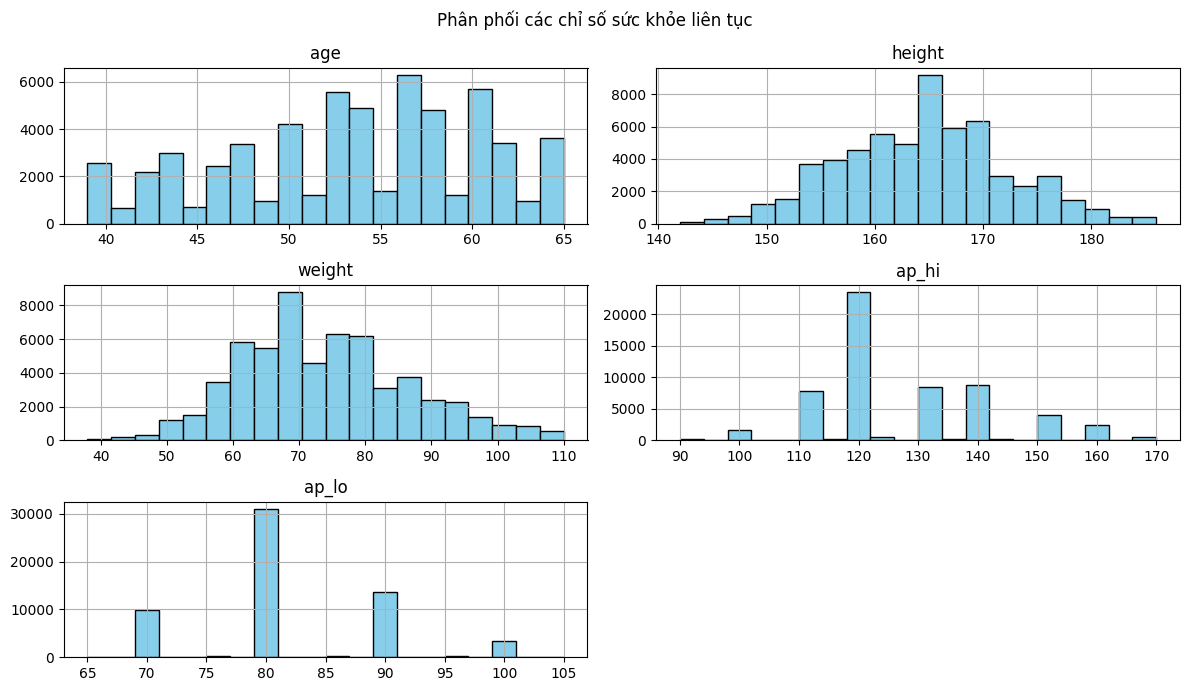

In [4]:
# Histogram phân phối các chỉ số thể chất và sức khỏe

# Danh sách các cột số liên tục cần vẽ
continuous_columns = ["age", "height", "weight", "ap_hi", "ap_lo"]

# Lấy riêng các cột cần vẽ ra một bảng nhỏ
continuous_data = cardio_data[continuous_columns]

# .hist() vẽ một histogram cho mỗi cột
# bins=20: chia dữ liệu thành 20 khoảng; edgecolor="black": viền đen cho mỗi cột
continuous_data.hist(figsize=(12, 7), bins=20, color="skyblue", edgecolor="black")

# suptitle() đặt tiêu đề chung cho cả hình
plt.suptitle("Phân phối các chỉ số sức khỏe liên tục")

# tight_layout() tự căn khoảng cách để các biểu đồ con không đè lên nhau
plt.tight_layout()
plt.show()

#### 1.2. So sánh người có bệnh và không có bệnh

Đường giữa mỗi hộp là trung vị. So sánh hai đường này để xem chỉ số nào thường cao hơn ở nhóm có bệnh.

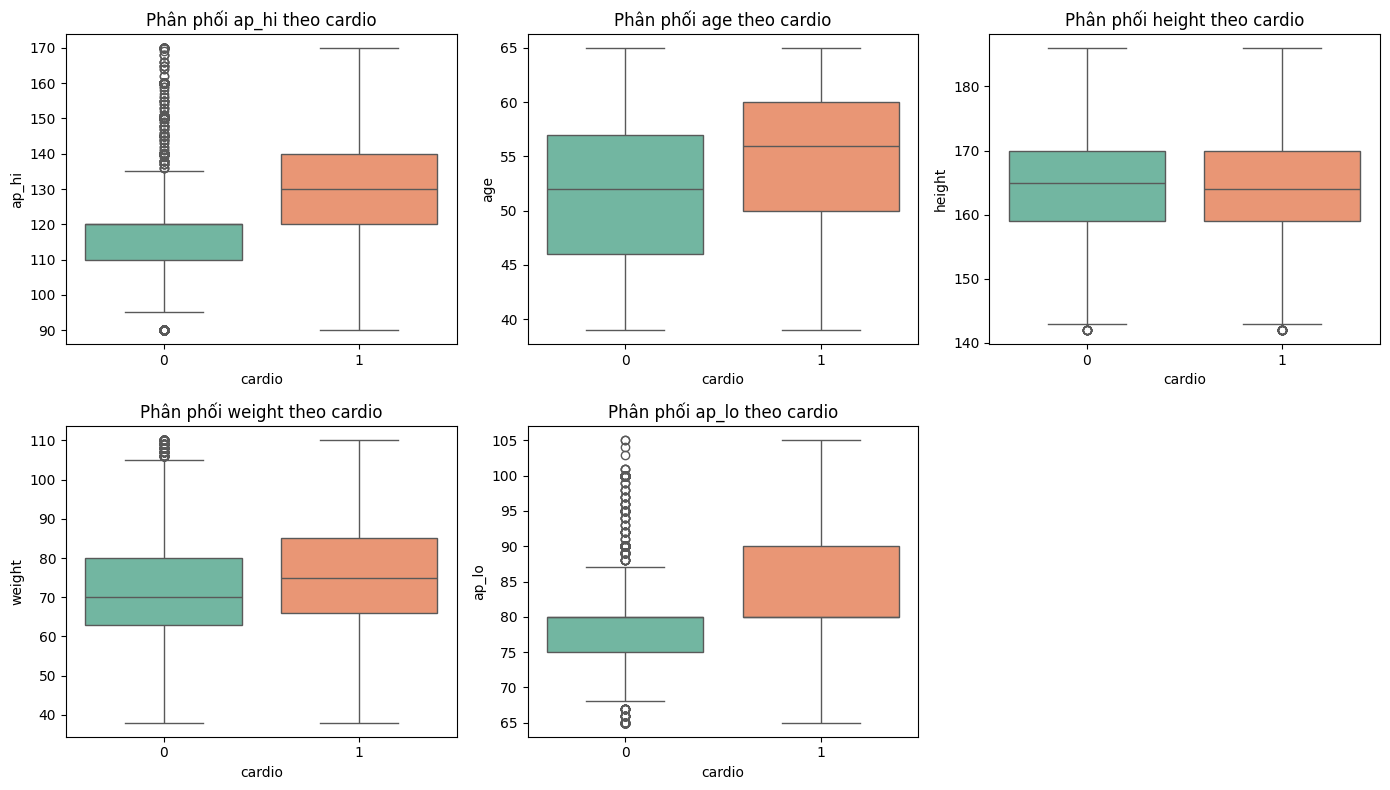

In [5]:
# Boxplot cho các biến liên tục phân theo nhóm cardio

# plt.subplots(2, 3) tạo một hình (figure) gồm 2 hàng x 3 cột = 6 ô biểu đồ (axis)
figure, axis_grid = plt.subplots(2, 3, figsize=(14, 8))

# .flatten() biến lưới 2 chiều thành danh sách 1 chiều để truy cập bằng 0, 1, 2, ...
axis_list = axis_grid.flatten()

numeric_columns = ["ap_hi", "age", "height", "weight", "ap_lo"]

# enumerate() trả về cùng lúc vị trí (0, 1, 2, ...) và giá trị trong danh sách
for position, column_name in enumerate(numeric_columns):
    current_axis = axis_list[position]

    # sns.boxplot() vẽ biểu đồ hộp: đường giữa hộp là trung vị
    sns.boxplot(data=cardio_data, x="cardio", y=column_name, hue="cardio", dodge=False, legend=False, ax=current_axis, palette="Set2")

    chart_title = "Phân phối " + column_name + " theo cardio"
    current_axis.set_title(chart_title)
    current_axis.set_xlabel("cardio")

# Chỉ có 5 cột nên xóa ô thứ 6 (vị trí 5) bị thừa
figure.delaxes(axis_list[5])
plt.tight_layout()
plt.show()

**Các biến phân loại và thói quen sinh hoạt.** Cholesterol được gộp vào nhóm biểu đồ này. Mỗi cột thể hiện số người theo từng mức của biến, tách theo nhãn cardio; hãy lưu ý quy mô từng nhóm khi so sánh.

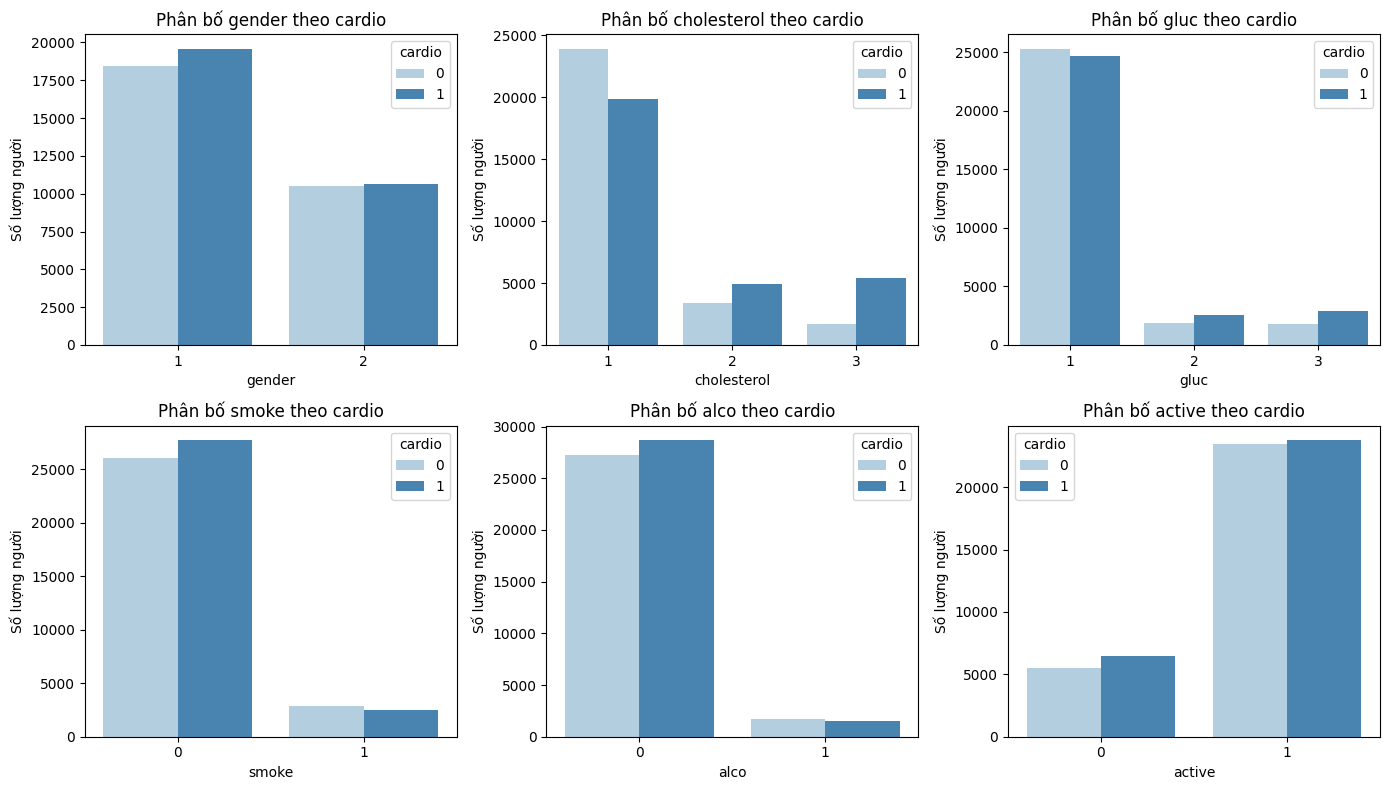

In [3]:
# Phân bố các biến phân loại và thói quen sinh hoạt theo cardio
category_columns = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

# Tạo hình gồm 2 hàng x 3 cột = 6 ô biểu đồ
figure, axis_grid = plt.subplots(2, 3, figsize=(14, 8))
axis_list = axis_grid.flatten()

for position, column_name in enumerate(category_columns):
    current_axis = axis_list[position]

    # Đếm số người theo từng giá trị của cột, tách màu theo nhãn cardio
    sns.countplot(data=cardio_data, x=column_name, hue="cardio", ax=current_axis, palette="Blues")

    chart_title = "Phân bố " + column_name + " theo cardio"
    current_axis.set_title(chart_title)
    current_axis.set_xlabel(column_name)
    current_axis.set_ylabel("Số lượng người")

plt.tight_layout()
plt.show()

#### 1.3. Chỉ số nào có tương quan với nhãn bệnh?

Hệ số dương cho biết hai biến có xu hướng tăng cùng nhau. Bỏ qua đường chéo vì mỗi biến được so với chính nó.

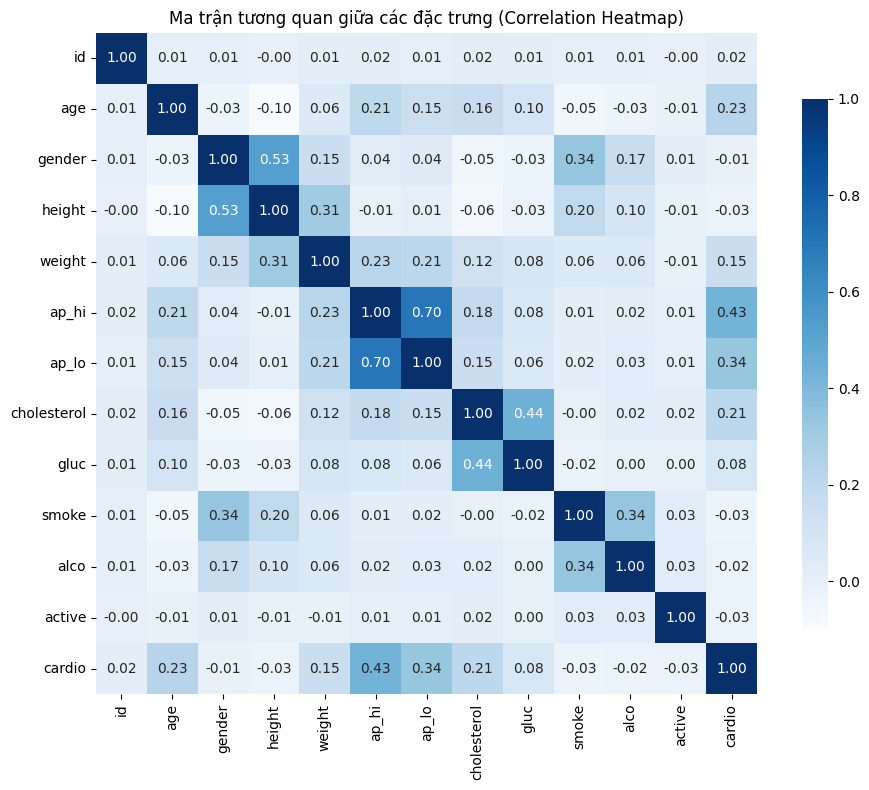

In [8]:
# Tính ma trận tương quan giữa các biến số

# Bước 1: select_dtypes(include="number") chỉ giữ lại các cột kiểu số
numeric_data = cardio_data.select_dtypes(include="number")

# Bước 2: .corr() tính hệ số tương quan giữa từng cặp cột
correlation_matrix = numeric_data.corr()

# Vẽ Heatmap trực quan
plt.figure(figsize=(10, 8))

# annot=True: ghi số lên mỗi ô; fmt=".2f": hiện 2 chữ số thập phân
# square=True: ô hình vuông; cbar_kws={"shrink": 0.8}: thanh màu thu nhỏ còn 80%
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Blues", square=True, cbar_kws={"shrink": 0.8})
plt.title("Ma trận tương quan giữa các đặc trưng (Correlation Heatmap)")
plt.tight_layout()
plt.show()

Đọc cột tương quan với `cardio`. Bỏ qua `id` vì đây chỉ là mã bản ghi.

In [9]:
# Bảng hệ số tương quan sắp xếp giảm dần theo mức độ ảnh hưởng tới cardio
print("Hệ số tương quan tuyến tính với biến mục tiêu cardio (sắp xếp giảm dần):")

# Bước 1: lấy cột "cardio" trong ma trận tương quan
cardio_correlation = correlation_matrix["cardio"]

# Bước 2: sắp xếp giảm dần
cardio_correlation = cardio_correlation.sort_values(ascending=False)

# Bước 3: .to_frame() đổi từ Series (1 cột) sang DataFrame (bảng) để hiển thị đẹp hơn
cardio_correlation_table = cardio_correlation.to_frame()

# Đặt lại tên cột
cardio_correlation_table.columns = ["Correlation with cardio"]
display(cardio_correlation_table)

Hệ số tương quan tuyến tính với biến mục tiêu cardio (sắp xếp giảm dần):


,Correlation with cardio
cardio,1.000000
ap_hi,0.429538
ap_lo,0.335058
age,0.231855
cholesterol,0.209871
weight,0.154334
gluc,0.075879
id,0.018645
gender,-0.012463
alco,-0.019457


**Nhận xét từ kết quả đã lưu.** Huyết áp tâm thu (`ap_hi`, 0,43) và tâm trương (`ap_lo`, 0,34) có tương quan dương cao nhất với nhãn bệnh trong các chỉ số được xét. Đây là mối liên hệ quan sát được trong bộ dữ liệu.